In [1]:
import logging
from collections import defaultdict
from collections.abc import Iterable, Mapping, Sequence
from functools import reduce
from itertools import product
from typing import Any

import colorcet as cc
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import wandb
from mpl_toolkits.axes_grid1 import make_axes_locatable


logger = logging.getLogger(__name__)


def reduce_fn(row, row_next):
    if row_next["loss_validation"] < row["loss_validation"]:
        return row_next
    else:
        return row


def get_sweep_results(
    entity: str,
    project: str,
    metric_names: list[str],
    hyperparam_names: list[str],
    config_filters: dict[str, Any] = dict(),
):
    api = wandb.Api()

    sweep_results = dict()
    for run in api.runs(
        f"{entity}/{project}",
        filters={"config." + k: v for k, v in config_filters.items()},
        lazy=False,
    ):
        logger.info("Fetching details for run: ", run.id, run.name)

        metrics_best = reduce(
            reduce_fn,
            run.scan_history(
                keys=["_step"] + [metric + "_validation" for metric in metric_names]
            ),
        )

        hyperparams = tuple(
            reduce(lambda d, k: d[k], hyper.split("."), run.config)
            for hyper in hyperparam_names
        )

        sweep_results[hyperparams] = metrics_best

    return sweep_results


def get_top_k(
    metrics: Sequence[tuple[Any, Mapping[str, float]]],
    sort_by: str,
    k: int | None = None,
    in_decreasing_order: bool = False,
):
    metrics_sorted = sorted(
        metrics, key=lambda x: x[1][sort_by], reverse=in_decreasing_order
    )
    return metrics_sorted[:k]


def get_grid_axes(hyperparams_list: Iterable[Sequence[Any]]) -> list[list[Any]]:
    # Use sets and for loops instead of np.unique and np.sort to handle non-numeric
    # types as well
    hparam_grids: dict[int, set[Any]] = defaultdict(set)
    for hparams in hyperparams_list:
        for i, val in enumerate(hparams):
            hparam_grids[i].add(val)
    return [sorted(list(hparam_grids[i])) for i in range(len(hparam_grids))]


def sweep_results_into_grid(
    sweep_results: Mapping[tuple[Any, ...], Mapping[str, float]],
) -> tuple[list[list[Any]], dict[str, np.ndarray]]:
    sweep_grids = defaultdict(list)
    hparam_axes = get_grid_axes(sweep_results.keys())
    for hparams in product(*hparam_axes):
        for k, v in sweep_results[hparams].items():
            sweep_grids[k].append(v)
    grid_shape = [len(g) for g in hparam_axes]
    sweep_grids = {k: np.asarray(v).reshape(grid_shape) for k, v in sweep_grids.items()}
    return hparam_axes, sweep_grids


In [2]:
def plot_sweep_results(
    sweep_results: Mapping[tuple[Any, ...], Mapping[str, float]],
    figsize: tuple[float, float],
    metric_names: list[str] | None = None,
    *,
    wspace: float = 0.25,
):
    hparam_axes, metrics_grid = sweep_results_into_grid(sweep_results)
    metric_names = list(metrics_grid.keys()) if metric_names is None else metric_names

    fig, axes = plt.subplots(
        1,
        len(metric_names),
        figsize=figsize,
        sharey=True,
        constrained_layout=True,
        gridspec_kw={"wspace": wspace},
    )
    for ax, name in zip(axes, metric_names):
        im = ax.imshow(
            metrics_grid[name],
            origin="lower",
            cmap=cc.m_coolwarm,
            norm=mcolors.LogNorm(),
        )
        ax.set_title(name, fontsize="medium")
        ax.set_xticks(np.arange(len(hparam_axes[1])), hparam_axes[1])
        ax.set_yticks(np.arange(len(hparam_axes[0])), hparam_axes[0])

        divider = make_axes_locatable(ax)
        cax = divider.append_axes("right", size="5%", pad=0.05)
        fig.colorbar(im, cax=cax, orientation="vertical")

    return fig


In [3]:
sweep_results = get_sweep_results(
    "jhko725",
    "lorenz63_revised",
    metric_names=["loss", "mmd_2", "mse"],
    hyperparam_names=["method.loss_fn.lambda_1", "method.loss_fn.lambda_2"],
    config_filters={
        "method.loss_fn._target_": "dynamics_discovery.loss_functions.DySLIMLoss",
        "model.key": 0,
        "data.noise_std_relative": 0.01,
    },
)

top3 = get_top_k(
    get_top_k(sweep_results.items(), sort_by="mmd_2_validation", k=3),
    sort_by="mse_validation",
)
top3

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /home/jhko725/.netrc.


[((0, 1),
  {'_step': 4876,
   'loss_validation': 1.7127529838540266e-06,
   'mmd_2_validation': 5.13380285406985e-07,
   'mse_validation': 1.1993726984470417e-06}),
 ((0, 10),
  {'_step': 4936,
   'loss_validation': 9.22872308252959e-06,
   'mmd_2_validation': 6.916652310924698e-07,
   'mse_validation': 2.312070771604892e-06}),
 ((0, 1000),
  {'_step': 4461,
   'loss_validation': 0.0009678473981152108,
   'mmd_2_validation': 9.635300169088058e-07,
   'mse_validation': 4.317381206405041e-06})]

Text(0.5, 0.98, 'Hyperparameter sweep results for DySLIM (Lorenz63)')

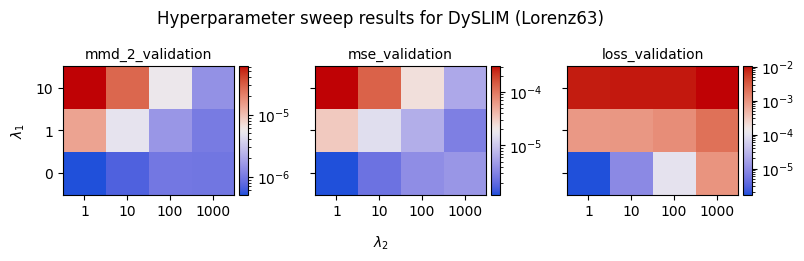

In [4]:
fig = plot_sweep_results(
    sweep_results,
    figsize=(7.5, 2.5),
    metric_names=["mmd_2_validation", "mse_validation", "loss_validation"],
)
fig.supylabel(r"$\lambda_1$", fontsize="medium")
fig.supxlabel(r"$\lambda_2$", fontsize="medium")
fig.suptitle("Hyperparameter sweep results for DySLIM (Lorenz63)")

## Efficient Neighborhood

In [8]:
sweep_results = get_sweep_results(
    "jhko725",
    "lorenz63_revised",
    metric_names=["loss", "loss_neighbors", "mse"],
    hyperparam_names=["method.loss_fn.weight", "method.loader_partial.num_neighbors"],
    config_filters={
        "method.name": "efficient_neighborhood",
        "model.key": 0,
        "data.noise_std_relative": 0.01,
    },
)

top3 = get_top_k(
    get_top_k(sweep_results.items(), sort_by="loss_neighbors_validation", k=3),
    sort_by="mse_validation",
)
top3

[((1000, 32),
  {'_step': 4415,
   'loss_validation': 0.03637589388760951,
   'loss_neighbors_validation': 3.637429736770728e-05,
   'mse_validation': 1.5965199022300894e-06}),
 ((100, 32),
  {'_step': 4415,
   'loss_validation': 0.0036579249070466716,
   'loss_neighbors_validation': 3.656317153533458e-05,
   'mse_validation': 1.6077535132138374e-06}),
 ((1, 32),
  {'_step': 4415,
   'loss_validation': 4.10541996558946e-05,
   'loss_neighbors_validation': 3.935143970981683e-05,
   'mse_validation': 1.7027599460777665e-06})]

Text(0.5, 0.98, 'Hyperparameter sweep results for EfficientNeighborhood (Lorenz63)')

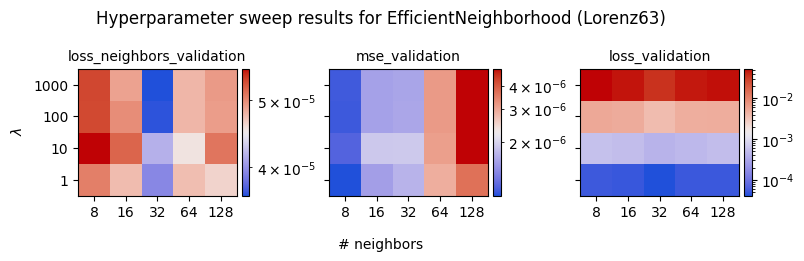

In [11]:
fig = plot_sweep_results(
    sweep_results,
    figsize=(7.5, 2.5),
    metric_names=["loss_neighbors_validation", "mse_validation", "loss_validation"],
    wspace=0.3,
)
fig.supylabel(r"$\lambda$", fontsize="medium")
fig.supxlabel("# neighbors", fontsize="medium")
fig.suptitle("Hyperparameter sweep results for EfficientNeighborhood (Lorenz63)")

# Lorenz 96 (6D)

In [10]:
sweep_results = get_sweep_results(
    "jhko725",
    "lorenz96_6d_revised",
    metric_names=["loss", "mmd_2", "mse"],
    hyperparam_names=["method.loss_fn.lambda_1", "method.loss_fn.lambda_2"],
    config_filters={
        "method.loss_fn._target_": "dynamics_discovery.loss_functions.DySLIMLoss",
        "model.key": 0,
        "data.noise_std_relative": 0.01,
    },
)

top3 = get_top_k(
    get_top_k(sweep_results.items(), sort_by="mse_validation", k=3),
    sort_by="mmd_2_validation",
)
top3

[((0, 1),
  {'_step': 4850,
   'loss_validation': 1.5568619551613175e-05,
   'mmd_2_validation': 2.7801331824496302e-06,
   'mse_validation': 1.2788486369163545e-05}),
 ((0, 10),
  {'_step': 4951,
   'loss_validation': 5.945687943320596e-05,
   'mmd_2_validation': 4.145842748031639e-06,
   'mse_validation': 1.7998451952889575e-05}),
 ((1, 1000),
  {'_step': 4955,
   'loss_validation': 0.006629920969705649,
   'mmd_2_validation': 5.229796814045904e-06,
   'mse_validation': 2.3966296520769887e-05})]

Text(0.5, 0.98, 'Hyperparameter sweep results for DySLIM (Lorenz96 6D)')

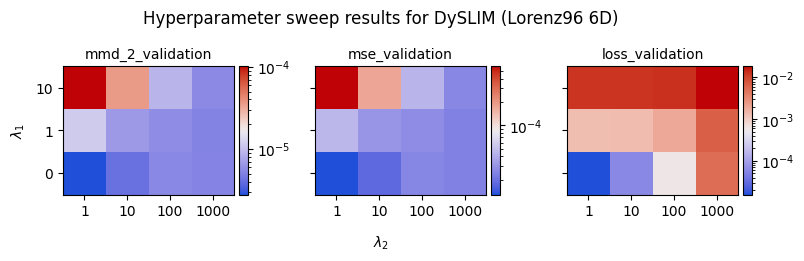

In [9]:
fig = plot_sweep_results(
    sweep_results,
    figsize=(7.5, 2.5),
    metric_names=["mmd_2_validation", "mse_validation", "loss_validation"],
)
fig.supylabel(r"$\lambda_1$", fontsize="medium")
fig.supxlabel(r"$\lambda_2$", fontsize="medium")
fig.suptitle("Hyperparameter sweep results for DySLIM (Lorenz96 6D)")

In [ ]:
sweep_results = get_sweep_results(
    "jhko725",
    "lorenz96_6d_revised",
    metric_names=["loss", "loss_neighbors", "mse"],
    hyperparam_names=["method.loss_fn.weight", "method.loader_partial.num_neighbors"],
    config_filters={
        "method.name": "efficient_neighborhood",
        "model.key": 0,
        "data.noise_std_relative": 0.01,
    },
)


[((100, 64),
  {'_step': 4361,
   'loss_validation': 0.017412105575203896,
   'loss_neighbors_validation': 0.00017398774798493832,
   'mse_validation': 1.3330697584024165e-05}),
 ((1000, 64),
  {'_step': 4361,
   'loss_validation': 0.1734146624803543,
   'loss_neighbors_validation': 0.00017340132035315037,
   'mse_validation': 1.3332532944332343e-05}),
 ((1, 128),
  {'_step': 4739,
   'loss_validation': 0.00019007410446647555,
   'loss_neighbors_validation': 0.00016863428754732013,
   'mse_validation': 2.143982237612363e-05})]

In [13]:
top3 = get_top_k(
    get_top_k(sweep_results.items(), sort_by="mse_validation", k=3),
    sort_by="loss_neighbors_validation",
)
top3

[((1, 8),
  {'_step': 4974,
   'loss_validation': 0.0004994476962908413,
   'loss_neighbors_validation': 0.0004958662627529282,
   'mse_validation': 3.5814335379130652e-06}),
 ((100, 8),
  {'_step': 4434,
   'loss_validation': 0.056016082873182896,
   'loss_neighbors_validation': 0.0005601139794878671,
   'mse_validation': 4.6849243961815545e-06}),
 ((1000, 8),
  {'_step': 4434,
   'loss_validation': 0.5611771987492796,
   'loss_neighbors_validation': 0.0005611724902102462,
   'mse_validation': 4.708539033488098e-06})]

Text(0.5, 0.98, 'Hyperparameter sweep results for EfficientNeighborhood (Lorenz96 6D)')

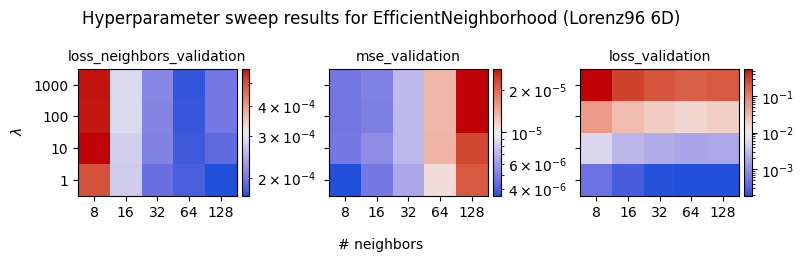

In [12]:
fig = plot_sweep_results(
    sweep_results,
    figsize=(7.5, 2.5),
    metric_names=["loss_neighbors_validation", "mse_validation", "loss_validation"],
    wspace=0.3,
)
fig.supylabel(r"$\lambda$", fontsize="medium")
fig.supxlabel("# neighbors", fontsize="medium")
fig.suptitle("Hyperparameter sweep results for EfficientNeighborhood (Lorenz96 6D)")

# Lorenz96 (18D)

In [3]:
sweep_results = get_sweep_results(
    "jhko725",
    "lorenz96_18d_revised",
    metric_names=["loss", "mmd_2", "mse"],
    hyperparam_names=["method.loss_fn.lambda_1", "method.loss_fn.lambda_2"],
    config_filters={
        "method.loss_fn._target_": "dynamics_discovery.loss_functions.DySLIMLoss",
        "model.key": 0,
        "data.noise_std_relative": 0.01,
    },
)

top3 = get_top_k(
    get_top_k(sweep_results.items(), sort_by="mmd_2_validation", k=3),
    sort_by="mse_validation",
)
top3

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /home/jhko725/.netrc.


[((0, 1),
  {'_step': 4981,
   'loss_validation': 0.0002466167393847672,
   'mmd_2_validation': 8.523831174788289e-05,
   'mse_validation': 0.0001613784276368843}),
 ((0, 10),
  {'_step': 4914,
   'loss_validation': 0.0011362082729726463,
   'mmd_2_validation': 9.474207080622812e-05,
   'mse_validation': 0.00018878756491036517}),
 ((1, 10),
  {'_step': 4969,
   'loss_validation': 0.002538876903998708,
   'mmd_2_validation': 9.481349730685316e-05,
   'mse_validation': 0.0001892542413302014})]

Text(0.5, 0.98, 'Hyperparameter sweep results for DySLIM (Lorenz96 6D)')

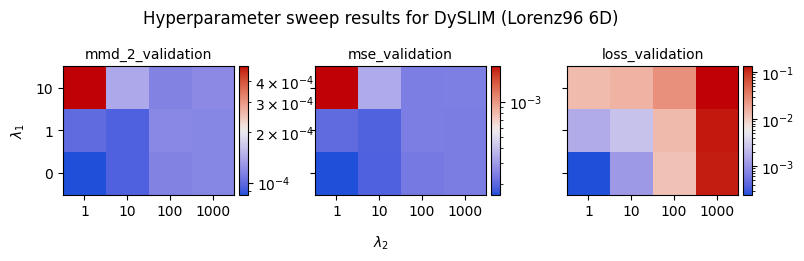

In [ ]:
fig = plot_sweep_results(
    sweep_results,
    figsize=(7.5, 2.5),
    metric_names=["mmd_2_validation", "mse_validation", "loss_validation"],
)
fig.supylabel(r"$\lambda_1$", fontsize="medium")
fig.supxlabel(r"$\lambda_2$", fontsize="medium")
fig.suptitle("Hyperparameter sweep results for DySLIM (Lorenz96 18D)")

In [5]:
sweep_results = get_sweep_results(
    "jhko725",
    "lorenz96_18d_revised",
    metric_names=["loss", "loss_neighbors", "mse"],
    hyperparam_names=["method.loss_fn.weight", "method.loader_partial.num_neighbors"],
    config_filters={
        "method.name": "efficient_neighborhood",
        "model.key": 0,
        "data.noise_std_relative": 0.01,
    },
)


In [6]:
top3 = get_top_k(
    get_top_k(sweep_results.items(), sort_by="mse_validation", k=3),
    sort_by="loss_neighbors_validation",
)
top3

[((1, 8),
  {'_step': 4981,
   'loss_validation': 0.01989045072195794,
   'loss_neighbors_validation': 0.019824054295511824,
   'mse_validation': 6.639642644611499e-05}),
 ((10, 8),
  {'_step': 4940,
   'loss_validation': 0.21219135102734168,
   'loss_neighbors_validation': 0.021211590371479464,
   'mse_validation': 7.54473125470566e-05}),
 ((100, 8),
  {'_step': 4940,
   'loss_validation': 2.142021255178433,
   'loss_neighbors_validation': 0.021419452242526366,
   'mse_validation': 7.60309257960765e-05})]

Text(0.5, 0.98, 'Hyperparameter sweep results for EfficientNeighborhood (Lorenz96 18D)')

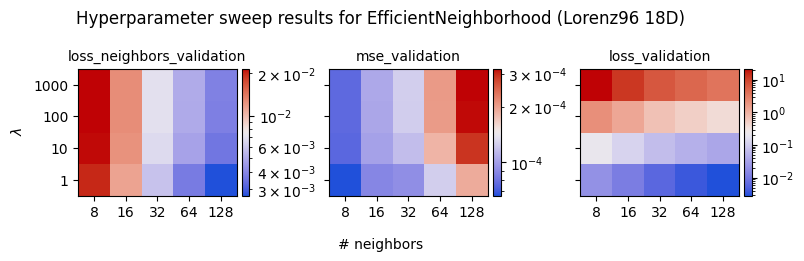

In [7]:
fig = plot_sweep_results(
    sweep_results,
    figsize=(7.5, 2.5),
    metric_names=["loss_neighbors_validation", "mse_validation", "loss_validation"],
    wspace=0.3,
)
fig.supylabel(r"$\lambda$", fontsize="medium")
fig.supxlabel("# neighbors", fontsize="medium")
fig.suptitle("Hyperparameter sweep results for EfficientNeighborhood (Lorenz96 18D)")